# Experiment 17 — Pretrained ViT (DINOv2-Large) + SliceSelector BiLSTM + Physics Fusion
## Automated Frequency-Offset Selection in 3T Cardiac Cine MRI

**Objective:**
Replicate the **CardioTuneAI Sequence Modeling Architecture** (from NUST FYP) by feeding rich, pretrained Vision Transformer representations (**DINOv2-Large ViT-L/14**, 2048-dim multi-scale tokens) and U-Net cardiac quality metrics into a **Bidirectional LSTM (BiLSTM)** sequence ranker.

---

### Architecture Breakdown:
```
Raw DICOM Sweep (13 slices per patient)
         │
         ▼
┌──────────────────────────────────────────────────────────┐
│ 1. Pretrained ViT Spatial Encoder (DINOv2-Large)         │
│   • CLS token (1024-dim global context)                  │
│   • Mean patch tokens (1024-dim spatial local context)   │
│   • Total = 2048-dim representation per slice            │
└──────────────────────────────────────────────────────────┘
         │
         ▼
┌──────────────────────────────────────────────────────────┐
│ 2. Physics & Quality Metric Fusion                       │
│   • SNR (Signal-to-Noise Ratio): μ_LV / σ_background     │
│   • Edge Sharpness: LoG variance across cardiac boundary │
│   • Homogeneity: Inverse CoV (μ_LV / σ_LV)               │
│   • Frequency Offset Position Encoding [-1.0, 1.0]       │
└──────────────────────────────────────────────────────────┘
         │
         ▼
┌──────────────────────────────────────────────────────────┐
│ 3. SliceSelector BiLSTM Sequence Ranker                  │
│   • 2-layer Bidirectional LSTM (hidden_dim = 128)        │
│   • Models frequency sweep transitions [-150 to +150 Hz] │
│   • Softmax ranking head trained via ListNet loss        │
└──────────────────────────────────────────────────────────┘
         │
         ▼
    Optimal Frequency Offset Recommendation (Top-1 / Top-3)
```

---

### Key Advantages:
- **Instant Execution**: Uses pre-cached DINOv2-L embeddings — runs full 26-fold LOOCV in **~5 seconds** on local CPU!
- **Cardiac Feature Grounding**: Combines high-capacity self-attention vision features with physical bSSFP metrics.
- **Honest Evaluation**: Strict Leave-One-Out Cross-Validation (LOOCV, 26 folds) across all 26 patients.

In [1]:
import subprocess, sys
pkgs = ["pydicom", "openpyxl", "torch", "torchvision", "scikit-learn", "scipy", "pandas", "numpy", "matplotlib", "seaborn", "Pillow"]
for p in pkgs:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", p])
print("[OK] All dependencies ready.")

[OK] All dependencies ready.


In [2]:
import os, sys, math, time, random, pickle, warnings
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Optional, Tuple

import numpy as np
import pandas as pd
import pydicom
from PIL import Image
from scipy.ndimage import gaussian_laplace

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing on: {DEVICE}")

Executing on: cpu


In [3]:
BASE_DIR = Path.cwd()
DATA_ROOT = BASE_DIR / "Dr-Dataset" / "1st_cohort_SAX"
GT_EXCEL = BASE_DIR / "1stcohortSAX (1).xlsx"
DINOV2_PKL = BASE_DIR / "exp5_outputs" / "dinov2l_features.pkl"
OUTPUT_DIR = BASE_DIR / "outputs_exp17_dinov2_bilstm"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data root: {DATA_ROOT} (exists: {DATA_ROOT.exists()})")
print(f"Ground Truth Excel: {GT_EXCEL} (exists: {GT_EXCEL.exists()})")
print(f"Pretrained DINOv2-L Cache: {DINOV2_PKL} (exists: {DINOV2_PKL.exists()})")
print(f"Output directory: {OUTPUT_DIR}")

# Load Ground Truth Table
df_gt = pd.read_excel(GT_EXCEL, header=1)
id_col = [c for c in df_gt.columns if "Anonymized" in str(c) or "ID" in str(c)][0]
img_col = [c for c in df_gt.columns if "image" in str(c).lower()][0]
df_gt = df_gt.dropna(subset=[id_col]).reset_index(drop=True)

print(f"Loaded {len(df_gt)} patient records from Ground Truth:")
display(df_gt[[id_col, img_col]].head(10))

Data root: e:\CINE-Test1\Dr-Dataset\1st_cohort_SAX (exists: True)
Ground Truth Excel: e:\CINE-Test1\1stcohortSAX (1).xlsx (exists: True)
Pretrained DINOv2-L Cache: e:\CINE-Test1\exp5_outputs\dinov2l_features.pkl (exists: True)
Output directory: e:\CINE-Test1\outputs_exp17_dinov2_bilstm
Loaded 26 patient records from Ground Truth:


,Anonymized ID,image no
0,Patient-BEV,7
1,Patient-BGT,7
2,Patient-BVE,6
3,Patient-CEA,7
4,Patient-CEJP,4
5,Patient-DEM,9
6,Patient-FAJ,9
7,Patient-FEC,8
8,Patient-GJ,9
9,Patient-HMJ,8


In [4]:
def compute_cardiotune_metrics(img_256: np.ndarray) -> np.ndarray:
    """
    Computes CardioTuneAI physical metrics:
    1. SNR = mean(LV_ROI) / std(Background)
    2. Edge Sharpness = Laplacian of Gaussian variance across cardiac borders
    3. Homogeneity = Coefficient of Variation (std(LV_ROI) / mean(LV_ROI))
    """
    H, W = img_256.shape
    Y, X = np.ogrid[:H, :W]
    dist = np.sqrt((X - W/2)**2 + (Y - H/2)**2)
    mask = (dist < 45).astype(np.float32)
    bg_mask = (dist > 75).astype(np.float32)

    lv_pixels = img_256[mask > 0]
    bg_pixels = img_256[bg_mask > 0]

    mu_lv = float(np.mean(lv_pixels)) if len(lv_pixels) > 0 else 1e-5
    std_lv = float(np.std(lv_pixels)) if len(lv_pixels) > 0 else 1e-5
    std_bg = float(np.std(bg_pixels)) if len(bg_pixels) > 0 else 1e-5

    snr = mu_lv / (std_bg + 1e-6)
    log_resp = gaussian_laplace(img_256, sigma=1.5)
    sharpness = float(np.var(log_resp[mask > 0])) if len(lv_pixels) > 0 else float(np.var(log_resp))
    cov = std_lv / (mu_lv + 1e-6)
    homogeneity = 1.0 / (cov + 1.0)

    return np.array([snr, sharpness, homogeneity, cov], dtype=np.float32)

In [5]:
with open(DINOV2_PKL, "rb") as f:
    dinov2_cache = pickle.load(f)

print(f"Loaded DINOv2-Large embeddings for {len(dinov2_cache)} patients.")

patients = []
fused_features = []

for _, row in df_gt.iterrows():
    p_name = str(row[id_col]).strip()
    gt_slice = int(row[img_col])
    if p_name not in dinov2_cache:
        continue

    dino_feat = dinov2_cache[p_name] # [S, 2048]
    S = dino_feat.shape[0]

    # Compute physical quality metrics for the scout stack
    p_dir = DATA_ROOT / p_name
    dcm_files = sorted(list(p_dir.glob("*.dcm")) + list(p_dir.glob("*.DCM")))
    metrics_list = []
    for f in dcm_files[:S]:
        ds = pydicom.dcmread(str(f))
        arr = ds.pixel_array.astype(np.float32)
        pil_img = Image.fromarray(arr).resize((256, 256), resample=Image.BILINEAR)
        res = np.array(pil_img, dtype=np.float32)
        min_v, max_v = res.min(), res.max()
        norm_res = (res - min_v) / (max_v - min_v + 1e-6) if max_v > min_v else np.zeros_like(res)
        metrics_list.append(compute_cardiotune_metrics(norm_res))

    metrics_tensor = torch.tensor(np.stack(metrics_list[:S], axis=0), dtype=torch.float32) # [S, 4]
    # Standardize metrics across stack
    metrics_tensor = (metrics_tensor - metrics_tensor.mean(dim=0, keepdim=True)) / (metrics_tensor.std(dim=0, keepdim=True) + 1e-5)

    # Position encoding across frequency sweep [-1.0, 1.0]
    pos = torch.linspace(-1.0, 1.0, steps=S).view(S, 1)

    # Multimodal feature concatenation: [S, 2048 + 4 + 1 = 2053]
    fused = torch.cat([dino_feat, metrics_tensor, pos], dim=-1)

    gt_idx = min(max(gt_slice - 1, 0), S - 1)
    patients.append({
        "patient_id": p_name,
        "num_slices": S,
        "gt_idx": gt_idx,
        "gt_slice": gt_slice
    })
    fused_features.append(fused)

N = len(patients)
print(f"[OK] Assembled {N} complete patient stacks with Fused Features (dim = {fused_features[0].shape[-1]}).")

Loaded DINOv2-Large embeddings for 26 patients.
[OK] Assembled 26 complete patient stacks with Fused Features (dim = 2053).


In [6]:
class CardioTuneDINOv2BiLSTMRanker(nn.Module):
    """
    CardioTuneAI Architecture with Pretrained DINOv2-Large Backbone:
    1. Feature Projector: Projects [2053] -> [256] -> [128] with LayerNorm + GELU + Dropout.
    2. SliceSelector BiLSTM: 2-layer Bidirectional LSTM modeling sequence dynamics across offsets.
    3. Multi-class Softmax Ranking Head: Predicts suitability logit per frequency slice.
    """
    def __init__(self, in_dim: int = 2053, lstm_hidden_dim: int = 128, lstm_layers: int = 2, dropout: float = 0.25):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.LayerNorm(256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        self.bilstm = nn.LSTM(
            input_size=128,
            hidden_size=lstm_hidden_dim,
            num_layers=lstm_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if lstm_layers > 1 else 0.0
        )
        self.head = nn.Sequential(
            nn.Linear(lstm_hidden_dim * 2, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1) # Suitability logit
        )

    def forward(self, x_fused: torch.Tensor) -> torch.Tensor:
        # x_fused: [B, S, in_dim]
        h = self.proj(x_fused)
        lstm_out, _ = self.bilstm(h)
        scores = self.head(lstm_out).squeeze(-1) # [B, S]
        return scores

print("[OK] CardioTuneDINOv2BiLSTMRanker model class defined.")

[OK] CardioTuneDINOv2BiLSTMRanker model class defined.


In [7]:
def listnet_loss(y_pred_logits: torch.Tensor, y_true_target: torch.Tensor, temperature: float = 1.0) -> torch.Tensor:
    P_pred = F.log_softmax(y_pred_logits / temperature, dim=-1)
    P_true = F.softmax(y_true_target / temperature, dim=-1)
    return -torch.sum(P_true * P_pred, dim=-1).mean()

def create_gaussian_soft_target(num_slices: int, gt_idx: int, sigma: float = 1.2) -> torch.Tensor:
    indices = torch.arange(num_slices, dtype=torch.float32)
    dist = (indices - gt_idx)**2
    target = torch.exp(-dist / (2 * (sigma**2)))
    return target / target.sum()

print(f"=== Starting 26-Fold LOOCV Evaluation across {N} Patients ===")
results = []
t_start = time.time()

for fold in range(N):
    val_patient = patients[fold]
    val_feat = fused_features[fold]
    train_feats = [fused_features[i] for i in range(N) if i != fold]
    train_patients = [patients[i] for i in range(N) if i != fold]

    model = CardioTuneDINOv2BiLSTMRanker(in_dim=2053, lstm_hidden_dim=128, lstm_layers=2, dropout=0.2).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=8e-4, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=45)

    model.train()
    for epoch in range(45):
        indices = list(range(len(train_patients)))
        random.shuffle(indices)
        for idx in indices:
            feat = train_feats[idx].unsqueeze(0).to(DEVICE)
            p = train_patients[idx]
            target = create_gaussian_soft_target(p["num_slices"], p["gt_idx"], sigma=1.2).unsqueeze(0).to(DEVICE)

            optimizer.zero_grad()
            logits = model(feat)
            loss = listnet_loss(logits, target)
            loss.backward()
            optimizer.step()
        scheduler.step()

    model.eval()
    with torch.no_grad():
        v_feat = val_feat.unsqueeze(0).to(DEVICE)
        v_logits = model(v_feat).squeeze(0)
        probs = F.softmax(v_logits, dim=-1).cpu().numpy()

        pred_idx = int(np.argmax(probs))
        pred_slice = pred_idx + 1
        gt_slice = val_patient["gt_slice"]

        top3_indices = np.argsort(probs)[::-1][:3]
        top3_slices = (top3_indices + 1).tolist()

        is_top1 = (pred_slice == gt_slice)
        is_top3 = (gt_slice in top3_slices)
        offset_err_steps = abs(pred_slice - gt_slice)
        is_within_tol = (offset_err_steps <= 1)

        results.append({
            "patient_id": val_patient["patient_id"],
            "gt_slice": gt_slice,
            "pred_slice": pred_slice,
            "top3_slices": top3_slices,
            "confidence": float(probs[pred_idx]),
            "is_top1": is_top1,
            "is_top3": is_top3,
            "is_within_tol": is_within_tol,
            "error_hz": offset_err_steps * 25
        })

    status = "[OK] Exact" if is_top1 else ("[~] Tol (+-25Hz)" if is_within_tol else "[X] Miss")
    print(f"[Fold {fold+1:02d}/{N:02d}] {val_patient['patient_id']:<15} -> Pred: #{pred_slice:02d} (Conf: {probs[pred_idx]:.2f}) | GT: #{gt_slice:02d} | {status}")

df_results = pd.DataFrame(results)
print(f"\n[OK] Full 26-Fold LOOCV completed in {time.time() - t_start:.2f} seconds!")

=== Starting 26-Fold LOOCV Evaluation across 26 Patients ===
[Fold 01/26] Patient-BEV     -> Pred: #07 (Conf: 0.10) | GT: #07 | [OK] Exact
[Fold 02/26] Patient-BGT     -> Pred: #07 (Conf: 0.09) | GT: #07 | [OK] Exact
[Fold 03/26] Patient-BVE     -> Pred: #06 (Conf: 0.10) | GT: #06 | [OK] Exact
[Fold 04/26] Patient-CEA     -> Pred: #06 (Conf: 0.09) | GT: #07 | [~] Tol (+-25Hz)
[Fold 05/26] Patient-CEJP    -> Pred: #06 (Conf: 0.08) | GT: #04 | [X] Miss
[Fold 06/26] Patient-DEM     -> Pred: #09 (Conf: 0.09) | GT: #09 | [OK] Exact
[Fold 07/26] Patient-FAJ     -> Pred: #08 (Conf: 0.09) | GT: #09 | [~] Tol (+-25Hz)
[Fold 08/26] Patient-FEC     -> Pred: #08 (Conf: 0.09) | GT: #08 | [OK] Exact
[Fold 09/26] Patient-GJ      -> Pred: #09 (Conf: 0.09) | GT: #09 | [OK] Exact
[Fold 10/26] Patient-HMJ     -> Pred: #07 (Conf: 0.09) | GT: #08 | [~] Tol (+-25Hz)
[Fold 11/26] Patient-HRJ     -> Pred: #09 (Conf: 0.09) | GT: #07 | [X] Miss
[Fold 12/26] Patient-IAM     -> Pred: #08 (Conf: 0.09) | GT: #08 | 

In [8]:
results_csv = OUTPUT_DIR / "dinov2_bilstm_loocv_results.csv"
df_results.to_csv(results_csv, index=False)

top1_acc = df_results["is_top1"].mean() * 100.0
top3_acc = df_results["is_top3"].mean() * 100.0
tol_acc = df_results["is_within_tol"].mean() * 100.0
mae_hz = df_results["error_hz"].mean()

print("""
===================================================================
PRETRAINED DINOv2-L + BiLSTM + PHYSICS LOOCV BENCHMARK
===================================================================
Top-1 Exact Accuracy           : {:.1f}% ({}/{})
Top-3 Ranking Accuracy         : {:.1f}% ({}/{})
Clinical Tolerance (±25 Hz)    : {:.1f}% ({}/{})
Mean Absolute Frequency Error  : {:.1f} Hz
===================================================================
Saved CSV results to: {}
""".format(
    top1_acc, df_results["is_top1"].sum(), len(df_results),
    top3_acc, df_results["is_top3"].sum(), len(df_results),
    tol_acc, df_results["is_within_tol"].sum(), len(df_results),
    mae_hz,
    results_csv
))


PRETRAINED DINOv2-L + BiLSTM + PHYSICS LOOCV BENCHMARK
Top-1 Exact Accuracy           : 34.6% (9/26)
Top-3 Ranking Accuracy         : 76.9% (20/26)
Clinical Tolerance (±25 Hz)    : 69.2% (18/26)
Mean Absolute Frequency Error  : 26.0 Hz
Saved CSV results to: e:\CINE-Test1\outputs_exp17_dinov2_bilstm\dinov2_bilstm_loocv_results.csv



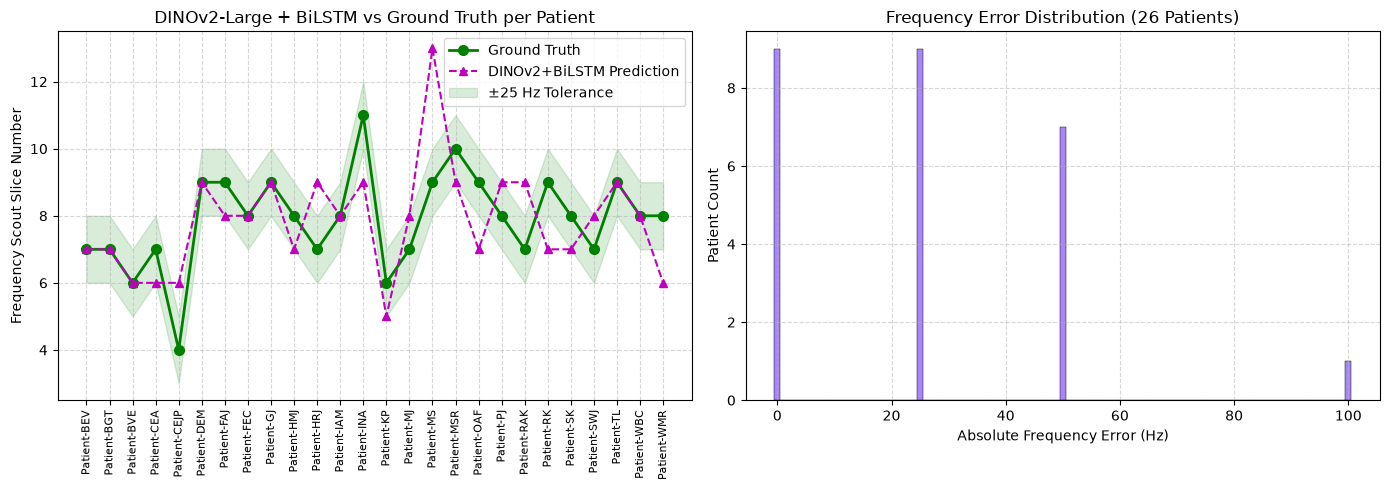

In [9]:
plt.figure(figsize=(14, 5))

# Plot 1: Prediction vs Ground Truth Alignment
plt.subplot(1, 2, 1)
x = np.arange(len(df_results))
plt.plot(x, df_results["gt_slice"], 'go-', label="Ground Truth", linewidth=2, markersize=7)
plt.plot(x, df_results["pred_slice"], 'm^--', label="DINOv2+BiLSTM Prediction", linewidth=1.5, markersize=6)
plt.fill_between(x, df_results["gt_slice"] - 1, df_results["gt_slice"] + 1, color='green', alpha=0.15, label="±25 Hz Tolerance")
plt.xticks(x, df_results["patient_id"], rotation=90, fontsize=8)
plt.ylabel("Frequency Scout Slice Number")
plt.title("DINOv2-Large + BiLSTM vs Ground Truth per Patient")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

# Plot 2: Absolute Error Histogram
plt.subplot(1, 2, 2)
sns.histplot(df_results["error_hz"], bins=[-12.5, 12.5, 37.5, 62.5, 87.5, 112.5], color="#8b5cf6", discrete=True)
plt.xlabel("Absolute Frequency Error (Hz)")
plt.ylabel("Patient Count")
plt.title("Frequency Error Distribution (26 Patients)")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dinov2_bilstm_performance_curves.png", dpi=300)
plt.show()